In [ ]:
import hashlib
import random
import pylab as plt
import math

In [ ]:
def hash_1000(key):
  key = repr(key).encode()
  return (int(hashlib.md5(key).hexdigest(),16) % 1000000)/1000.0

In [ ]:
def bin_range_assignment(machines,replicas):
  points = [[0]]
  for i in range(machines):
    for g in range(replicas + 1):
      points.append([hash_1000(str(i)+'replica'+str(g)),i])
  points.append([1000.1,points[1][1]])
  return sorted(points)

In [ ]:
def range_bins(sorted_points):
  ranges = []
  for i in range(1,len(sorted_points)):
    under_range = sorted_points[i-1][0]
    ranges.append([(under_range,sorted_points[i][0]),sorted_points[i][1]])

  return ranges

In [ ]:
def task_to_server(ranges,item):
  hash_val = hash_1000(item)
  #print(hash_val)
  index_bin = 0
  for i in range(len(ranges)):
    if ranges[i][0][1] > hash_val:
      index_bin = ranges[i][1]
      break
  return index_bin

In [ ]:
def server_task_simulation(task_count,servers,replicas):
  ranges = range_bins(bin_range_assignment(servers,replicas))
  server_to_tasks = {i:0 for i in range(servers)}
  tasks = ['task'+str(i) for i in range(task_count)]
  for i in tasks:
    index = task_to_server(ranges,i)
    server_to_tasks[index] += 1
  x = list(server_to_tasks.keys())
  x.sort()
  y = list(server_to_tasks.values())
  y.sort()
  y.reverse()
  plt.plot(x,y)
  plt.xlabel("Servers")
  plt.title("Consistent Hashing Simulation"+" "+ "Replicas:"+" " +str(replicas -1))
  plt.ylabel("Server Load")
  division = task_count/servers
  plt.hlines(division,0,1000,'r')
  return server_to_tasks

In [ ]:
hash_1000(2)


479.212

In [ ]:
hash_1000(3)

880.883

In [ ]:
hash_1000(1)

88.411

In [ ]:
hash_1000('1'+'replica'+'1')

274.798

In [ ]:
hash_1000('1'+'replica'+'2')

497.187

In [ ]:
bin_range_assignment(10,1)

[[0],
 [1.179, 3],
 [28.222, 4],
 [45.596, 8],
 [52.304, 4],
 [61.191, 6],
 [91.073, 5],
 [166.403, 7],
 [181.116, 2],
 [274.798, 1],
 [367.428, 9],
 [393.046, 9],
 [413.021, 7],
 [435.193, 6],
 [505.135, 0],
 [521.601, 8],
 [630.271, 1],
 [670.86, 2],
 [823.228, 0],
 [844.83, 5],
 [875.587, 3],
 [1000.1, 0]]

In [ ]:
range_bins(bin_range_assignment(10,1))

[[(0, 1.179), 3],
 [(1.179, 28.222), 4],
 [(28.222, 45.596), 8],
 [(45.596, 52.304), 4],
 [(52.304, 61.191), 6],
 [(61.191, 91.073), 5],
 [(91.073, 166.403), 7],
 [(166.403, 181.116), 2],
 [(181.116, 274.798), 1],
 [(274.798, 367.428), 9],
 [(367.428, 393.046), 9],
 [(393.046, 413.021), 7],
 [(413.021, 435.193), 6],
 [(435.193, 505.135), 0],
 [(505.135, 521.601), 8],
 [(521.601, 630.271), 1],
 [(630.271, 670.86), 2],
 [(670.86, 823.228), 0],
 [(823.228, 844.83), 5],
 [(844.83, 875.587), 3]]

In [ ]:
task_to_server(range_bins(bin_range_assignment(10,1)),10)

601.824


1

In [ ]:
def statistics_balls_and_bins(simulation_dictionary):
  #Maximum Load
  simulation_vals = list(simulation_dictionary.values())
  simulation_keys = list(simulation_dictionary.keys())
  print("Max Load: ",max(simulation_vals))
  
  
  print("Min Load: ", min(simulation_vals))
  
  print("Bin Range: ", min(simulation_vals),"-", max(simulation_vals))
  
  
  print("Expected Tasks in Server: ", 100)
  
  sums_squared = 0
  expected = sum(simulation_vals)/len(simulation_keys)
  for i in simulation_vals:
    sums_squared += (i-100)**2
  variance = sums_squared / len(simulation_vals)
  print("Variance: ", variance)
  
  print("Standard Deviation: ", round(variance**0.5,4))
  
  bins_below_average = 0
  bins_above_average = 0
  bins_at_average = 0
  for i in simulation_keys:
    if simulation_dictionary[i] > 100:
      bins_above_average += 1
    elif simulation_dictionary[i] == 100:
      bins_at_average += 1
    else:
      bins_below_average += 1
  print("Server Task Count Below Average: ", bins_below_average)
  
  print("Server Task Count at Average: ", bins_at_average)
  
  print("Server Task Count Above Average: ", bins_above_average)

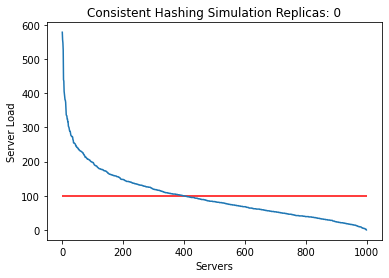

In [ ]:
sim_1 = server_task_simulation(100000,1000,1)

In [ ]:
statistics_balls_and_bins(sim_1)

Max Load:  579
Min Load:  0
Bin Range:  0 - 579
Expected Tasks in Server:  100
Variance:  5870.754
Standard Deviation:  76.6208
Server Task Count Below Average:  599
Server Task Count at Average:  5
Server Task Count Above Average:  396


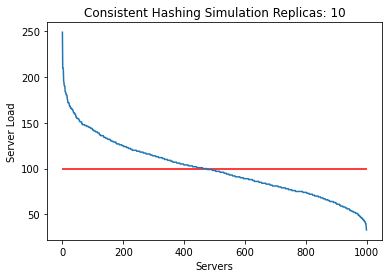

In [ ]:
sim_2 = server_task_simulation(100000,1000,11)

In [ ]:
statistics_balls_and_bins(sim_2)

Max Load:  249
Min Load:  33
Bin Range:  33 - 249
Expected Tasks in Server:  100
Variance:  970.602
Standard Deviation:  31.1545
Server Task Count Below Average:  524
Server Task Count at Average:  15
Server Task Count Above Average:  461


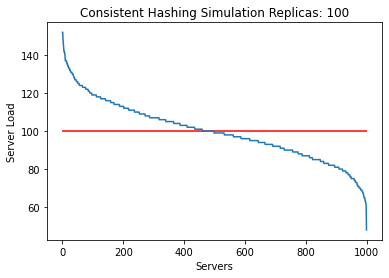

In [ ]:
sim_3 = server_task_simulation(100000,1000,101)

In [ ]:
statistics_balls_and_bins(sim_3)

Max Load:  152
Min Load:  48
Bin Range:  48 - 152
Expected Tasks in Server:  100
Variance:  232.976
Standard Deviation:  15.2636
Server Task Count Below Average:  502
Server Task Count at Average:  38
Server Task Count Above Average:  460


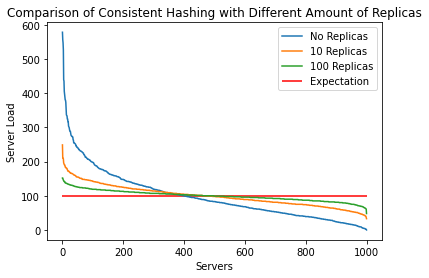

In [ ]:
x = list(sim_1.keys())
x.sort()
y = list(sim_1.values())
y.sort()
y.reverse()
y_2 = list(sim_2.values())
y_2.sort()
y_2.reverse()
y_3 = list(sim_3.values())
y_3.sort()
y_3.reverse()
plt.figure()
plt.plot(x,y,label="No Replicas")
plt.plot(x,y_2,label="10 Replicas")
plt.plot(x,y_3,label="100 Replicas")
plt.title("Comparison of Consistent Hashing with Different Amount of Replicas")
plt.xlabel("Servers")
plt.ylabel("Server Load")
plt.hlines(100,0,1000,'r',label="Expectation")
plt.legend()

#Biased Data Generation

In [ ]:
def geom_pmf(p,k):
  return (1-p)**(k-1) * p

In [ ]:
def generate_range_geom(p):
  x = [1]
  y = [geom_pmf(p,1)]
  for i in range(2,100):
    y.append(float(y[i-2])+geom_pmf(p,i))
    x.append(i)
  return x,y

In [ ]:
def generate_data_geom(p,n):
  ranges = generate_range_geom(p)
  prob_to_num = {}
  sort_range = sorted(ranges[1])
  for i in range(len(ranges[0])):
    prob_to_num[ranges[1][i]] = ranges[0][i]
  list_of_tasks = []
  for i in range(n):
    interval = random.random()
    #print(interval)
    for num in sort_range:
      if interval < num:
        list_of_tasks.append(prob_to_num[num])
        break
  return list_of_tasks,len(list_of_tasks)

In [ ]:
generate_data_geom(0.7,100000)

In [ ]:
def test_data_follow_distribution(p,n,sample=False):
  x = []
  y = []
  y_2 = []
  data = generate_data_geom(p,n*100)
  data = data[0]
  #print(data)
  for i in range(1,100):
    x.append(i)
    #print(data.count(i),len(data))
    y.append(data.count(i)/len(data))
    y_2.append(geom_pmf(p,i))
  #return x,y,y_2
  if sample == True:
    plt.plot(x,y,label = "Sample")
    plt.title("Sample Data vs. PMF: Two Lines on Graph")
    plt.ylabel("Probability")
    plt.xlabel("Object Number")
    plt.plot(x,y_2, label = "PMF")
    plt.legend()
  else:
    plt.ylabel("Probability")
    plt.xlabel("Object Number")
    plt.plot(x,y_2, label = "PMF")
    plt.title("Geometric PMF")
    plt.legend()

In [ ]:
a = test_data_follow_distribution(0.5,100)
print(sum(a[1]),sum(a[2]))

0.9999999999999999 1.0


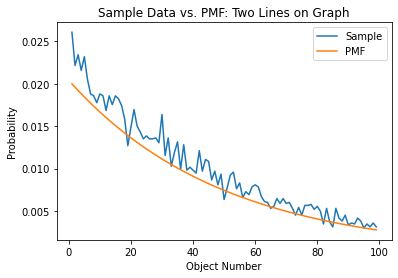

In [ ]:
test_data_follow_distribution(0.02,100,True)

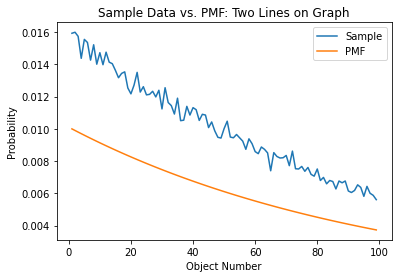

In [ ]:
test_data_follow_distribution(0.01,1000,True)

In [ ]:
generate_range_geom(0.8)

([1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
 [0.8,
  0.96,
  0.992,
  0.9984,
  0.9996799999999999,
  0.9999359999999999,
  0.9999872,
  0.99999744,
  0.999999488,
  0.9999998976000001])

In [ ]:
print(generate_data_geom(0.8,10))

([1, 1, 1, 1, 1, 1, 3, 1, 1, 1], 10)


In [ ]:
def server_task_simulation_biased(tasks,servers,replicas):
  ranges = range_bins(bin_range_assignment(servers,replicas))
  server_to_tasks = {i:0 for i in range(servers)}
  tasks = tasks[0]
  task_count = len(tasks)
  for i in tasks:
    index = task_to_server(ranges,i)
    server_to_tasks[index] += 1
  x = list(server_to_tasks.keys())
  x.sort()
  y = list(server_to_tasks.values())
  y.sort()
  y.reverse()
  plt.plot(x,y)
  plt.xlabel("Servers")
  plt.title("Consistent Hashing Simulation"+" "+ "Replicas:"+" " +str(replicas -1))
  plt.ylabel("Server Load")
  division = task_count/servers
  plt.hlines(division,0,1000,'r')
  return server_to_tasks, sum(list(server_to_tasks.values()))

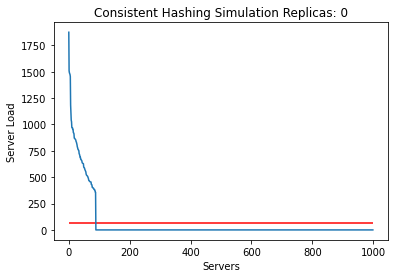

In [ ]:
sim_1 = server_task_simulation_biased(generate_data_geom(0.01,100000),1000,1)

In [ ]:
statistics_balls_and_bins(sim_1[0])

Max Load:  1937
Min Load:  0
Bin Range:  0 - 1937
Expected Tasks in Server:  100
Variance:  49909.463
Standard Deviation:  223.4043
Server Task Count Below Average:  911
Server Task Count at Average:  0
Server Task Count Above Average:  89


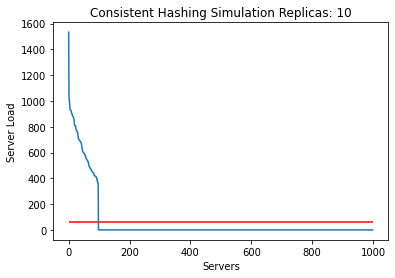

In [ ]:
sim_2 = server_task_simulation_biased(generate_data_geom(0.01,100000),1000,11)

In [ ]:
statistics_balls_and_bins(sim_2[0])

Max Load:  1436
Min Load:  0
Bin Range:  0 - 1436
Expected Tasks in Server:  100
Variance:  42026.702
Standard Deviation:  205.0042
Server Task Count Below Average:  902
Server Task Count at Average:  0
Server Task Count Above Average:  98


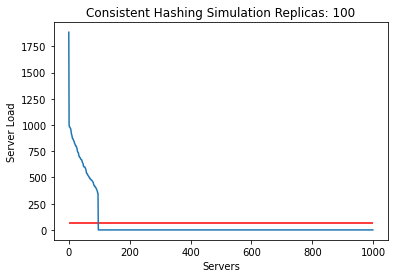

In [ ]:
sim_3 = server_task_simulation_biased(generate_data_geom(0.01,100000),1000,101)

In [ ]:
statistics_balls_and_bins(sim_3[0])

Max Load:  1884
Min Load:  0
Bin Range:  0 - 1884
Expected Tasks in Server:  100
Variance:  43114.096
Standard Deviation:  207.6393
Server Task Count Below Average:  903
Server Task Count at Average:  0
Server Task Count Above Average:  97


In [ ]:
sim_4 = server_task_simulation_biased(generate_data_geom(0.01,100000),1000,501)

In [ ]:
statistics_balls_and_bins(sim_4[0])

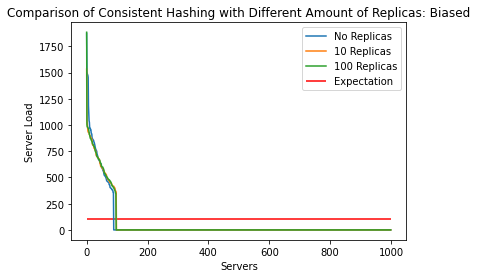

In [ ]:
x = list(sim_1[0].keys())
x.sort()
y = list(sim_1[0].values())
y.sort()
y.reverse()
y_2 = list(sim_2[0].values())
y_2.sort()
y_2.reverse()
y_3 = list(sim_3[0].values())
y_3.sort()
y_3.reverse()
plt.figure()
plt.plot(x,y,label="No Replicas")
plt.plot(x,y_2,label="10 Replicas")
plt.plot(x,y_3,label="100 Replicas")
plt.title("Comparison of Consistent Hashing with Different Amount of Replicas: Biased")
plt.xlabel("Servers")
plt.ylabel("Server Load")
plt.hlines(100,0,1000,'r',label="Expectation")
plt.legend()

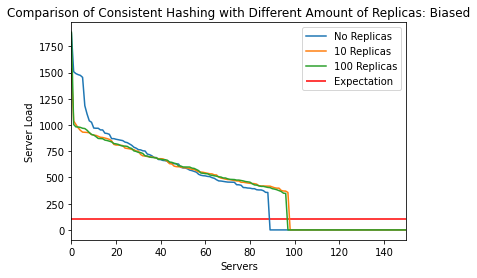

In [ ]:
x = list(sim_1[0].keys())
x.sort()
y = list(sim_1[0].values())
y.sort()
y.reverse()
y_2 = list(sim_2[0].values())
y_2.sort()
y_2.reverse()
y_3 = list(sim_3[0].values())
y_3.sort()
y_3.reverse()
plt.figure()
plt.plot(x,y,label="No Replicas")
plt.plot(x,y_2,label="10 Replicas")
plt.plot(x,y_3,label="100 Replicas")
plt.xlim(0,150)
plt.title("Comparison of Consistent Hashing with Different Amount of Replicas: Biased")
plt.xlabel("Servers")
plt.ylabel("Server Load")
plt.hlines(100,0,1000,'r',label="Expectation")
plt.legend()